In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
df = pd.read_csv("../data/customer.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Columns:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome           

In [5]:
print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


Duplicate Rows: 0


In [6]:
print(df.columns.tolist())
print(df.shape)

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']
(2240, 29)


In [7]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows containing missing values
df = df.dropna()

print("Dataset shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum().sum())

Dataset shape after cleaning: (2216, 29)

Remaining missing values:
0


In [8]:
print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

display(df.describe())

Numerical columns:
['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,49.012635,305.091606,26.356047,166.995939,37.637635,...,5.319043,0.073556,0.074007,0.073105,0.064079,0.013538,0.009477,3.0,11.0,0.150271
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,28.948352,337.327920,39.793917,224.283273,54.752082,...,2.425359,0.261106,0.261842,0.260367,0.244950,0.115588,0.096907,0.0,0.0,0.357417
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,174.500000,8.000000,68.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Available numerical features:")
for column in numeric_columns:
    print("-", column)

Available numerical features:
- ID
- Year_Birth
- Income
- Kidhome
- Teenhome
- Recency
- MntWines
- MntFruits
- MntMeatProducts
- MntFishProducts
- MntSweetProducts
- MntGoldProds
- NumDealsPurchases
- NumWebPurchases
- NumCatalogPurchases
- NumStorePurchases
- NumWebVisitsMonth
- AcceptedCmp3
- AcceptedCmp4
- AcceptedCmp5
- AcceptedCmp1
- AcceptedCmp2
- Complain
- Z_CostContact
- Z_Revenue
- Response


In [10]:
print(df.columns.tolist())
print(df.select_dtypes(include=np.number).columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']
['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [12]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [13]:
print(df.select_dtypes(include=np.number).columns.tolist())

['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [14]:
# Create total spending across product categories
df["Total_Spending"] = (
    df["MntWines"] +
    df["MntFruits"] +
    df["MntMeatProducts"] +
    df["MntFishProducts"] +
    df["MntSweetProducts"] +
    df["MntGoldProds"]
)

# Create total number of purchases across channels
df["Total_Purchases"] = (
    df["NumWebPurchases"] +
    df["NumCatalogPurchases"] +
    df["NumStorePurchases"]
)

# Select features for clustering
features = [
    "Income",
    "Recency",
    "Total_Spending",
    "NumDealsPurchases",
    "Total_Purchases",
    "NumWebVisitsMonth"
]

X = df[features].copy()

print("Selected clustering features:")
print(features)

print("\nFeature shape:", X.shape)

display(X.head())

Selected clustering features:
['Income', 'Recency', 'Total_Spending', 'NumDealsPurchases', 'Total_Purchases', 'NumWebVisitsMonth']

Feature shape: (2216, 6)


,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth
0,58138.0,58,1617,3,22,7
1,46344.0,38,27,2,4,5
2,71613.0,26,776,1,20,4
3,26646.0,26,53,2,6,6
4,58293.0,94,422,5,14,5


In [15]:
print("Missing values:")
display(X.isnull().sum())

print("\nFeature statistics:")
display(X.describe())

Missing values:


Income               0
Recency              0
Total_Spending       0
NumDealsPurchases    0
Total_Purchases      0
NumWebVisitsMonth    0
dtype: int64


Feature statistics:


,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,52247.251354,49.012635,607.075361,2.323556,12.557310,5.319043
std,25173.076661,28.948352,602.900476,1.923716,7.204611,2.425359
min,1730.000000,0.000000,5.000000,0.000000,0.000000,0.000000
25%,35303.000000,24.000000,69.000000,1.000000,6.000000,3.000000
50%,51381.500000,49.000000,396.500000,2.000000,12.000000,6.000000
75%,68522.000000,74.000000,1048.000000,3.000000,18.000000,7.000000
max,666666.000000,99.000000,2525.000000,15.000000,32.000000,20.000000


In [16]:
X = X.dropna()

print("Shape after removing missing values:", X.shape)

Shape after removing missing values: (2216, 6)


In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Scaled features:")
display(X_scaled.head())

Scaled features:


,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth
0,0.234063,0.310532,1.675488,0.351713,1.310941,0.693232
1,-0.234559,-0.380509,-0.962358,-0.168231,-1.188023,-0.131574
2,0.769478,-0.795134,0.280250,-0.688176,1.033278,-0.543978
3,-1.017239,-0.795134,-0.919224,-0.168231,-0.910360,0.280829
4,0.240221,1.554407,-0.307044,1.391603,0.200291,-0.131574


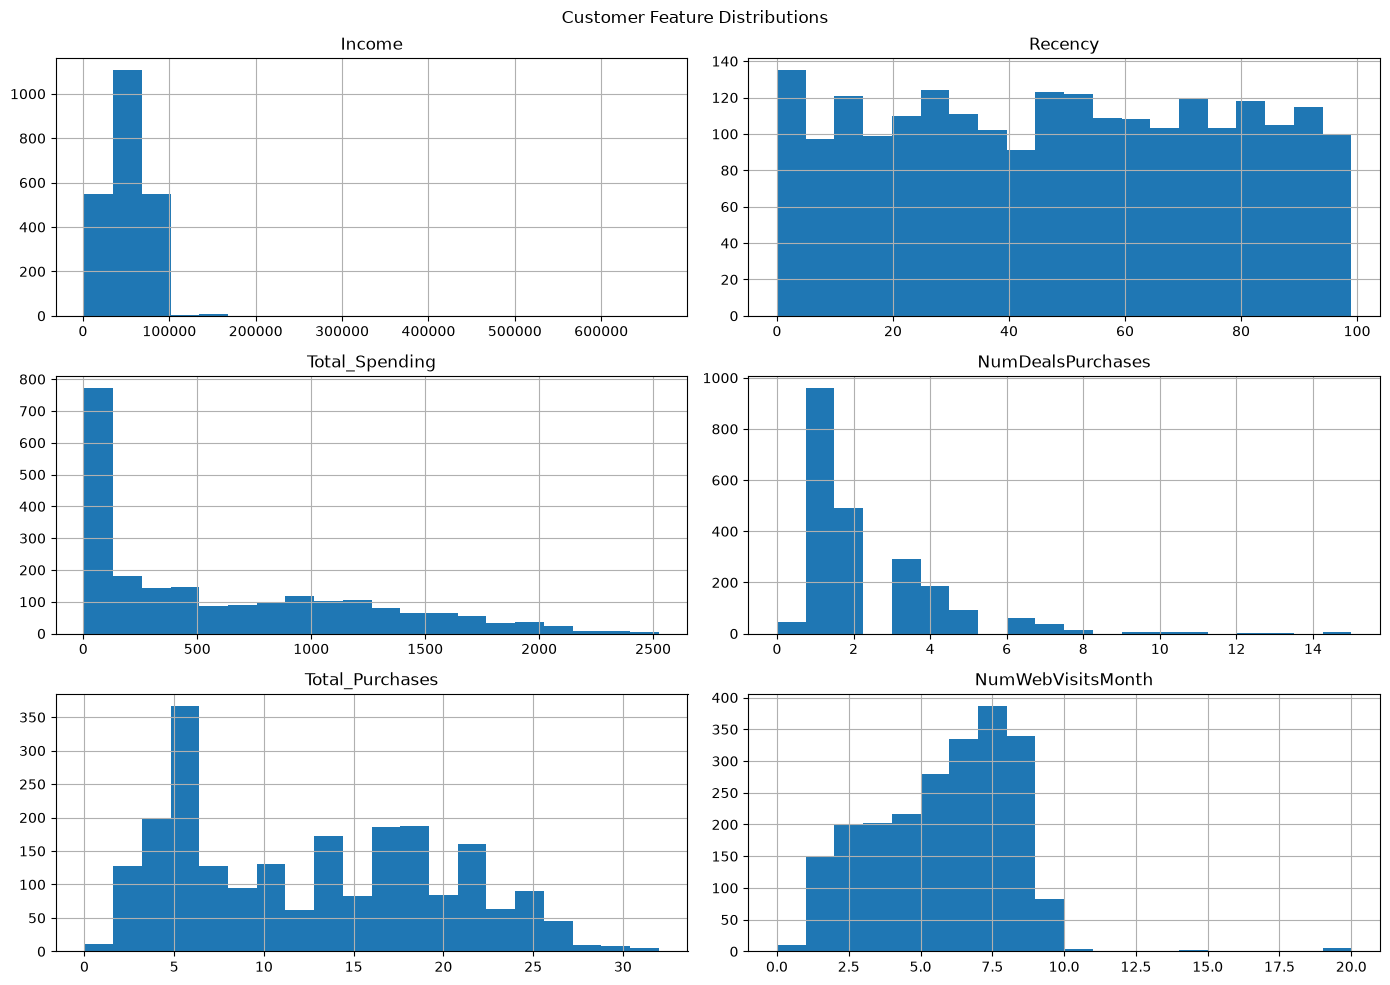

In [18]:
X.hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Customer Feature Distributions")
plt.tight_layout()
plt.show()

In [19]:
plt.savefig(
    "../visuals/feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1200x600 with 0 Axes>

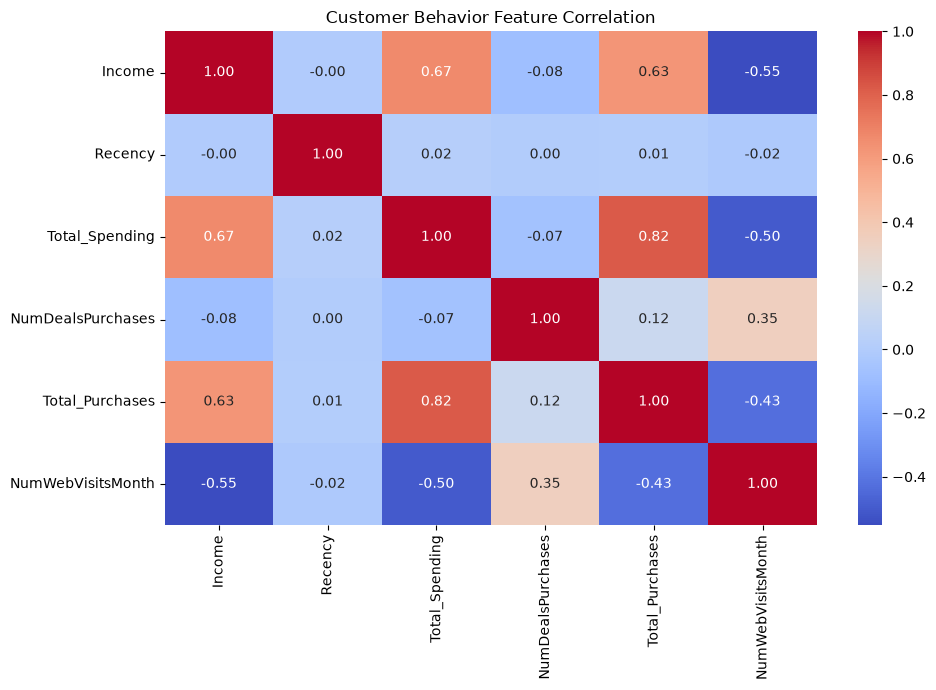

In [20]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Behavior Feature Correlation")
plt.tight_layout()

plt.savefig(
    "../visuals/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

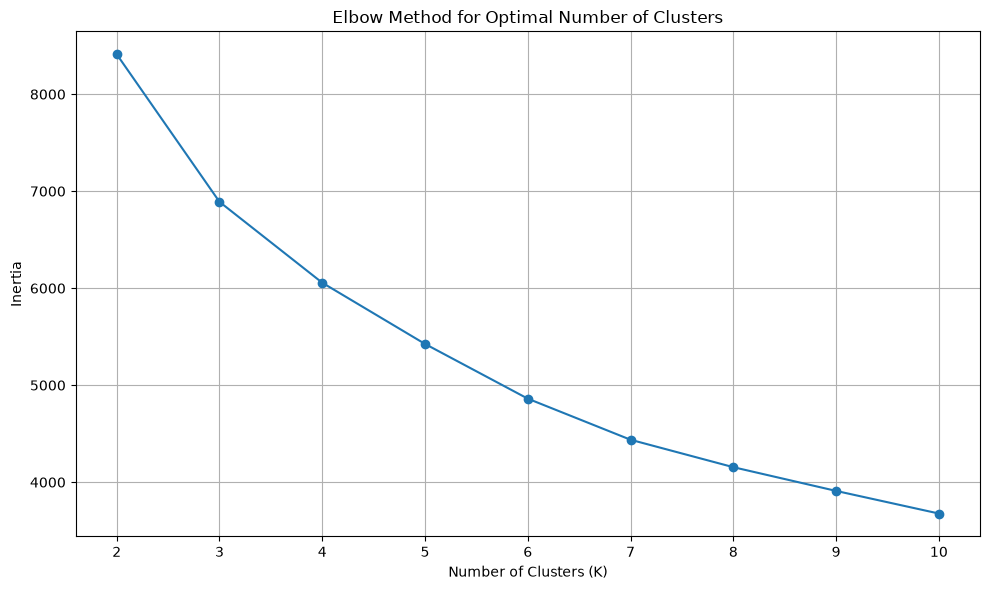

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(K_range))
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../visuals/elbow_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(
        X_scaled,
        labels
    )
    
    silhouette_scores.append(score)

silhouette_results = pd.DataFrame({
    "K": list(K_range),
    "Silhouette_Score": silhouette_scores
})

display(silhouette_results)

,K,Silhouette_Score
0,2,0.360251
1,3,0.338418
2,4,0.281920
3,5,0.247991
4,6,0.248727
5,7,0.249524
6,8,0.244109
7,9,0.241271
8,10,0.236283


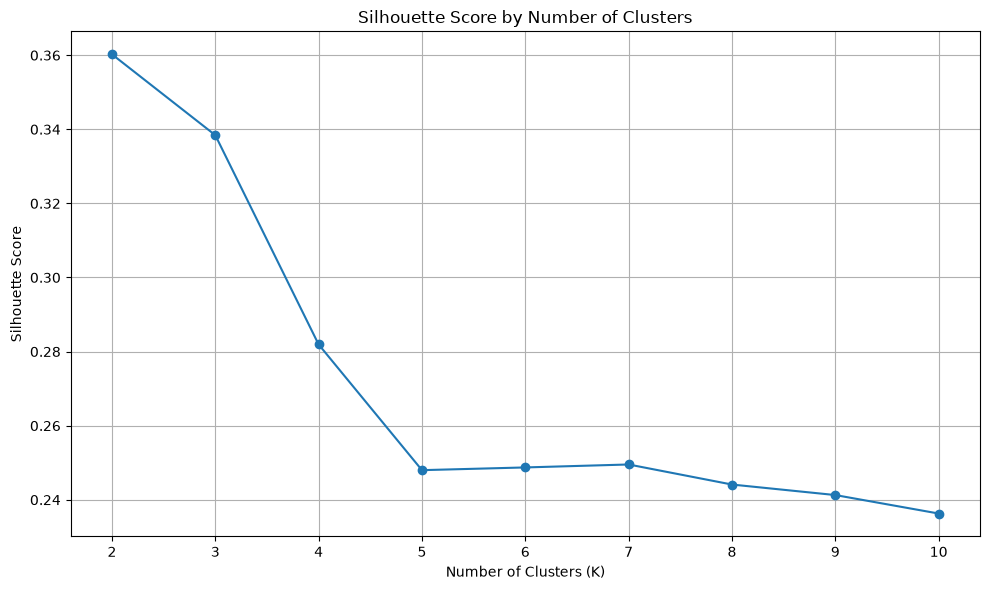

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

print("K-Means clustering completed.")
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

K-Means clustering completed.

Cluster counts:
Cluster
0    562
1    330
2    535
3    789
Name: count, dtype: int64


In [26]:
cluster_profile = df.groupby("Cluster")[features].mean().round(2)

display(cluster_profile)

,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth
Cluster,,,,,,
0,34816.19,24.03,120.60,1.93,6.37,6.50
1,53800.62,48.24,705.82,5.72,16.54,6.85
2,36728.22,75.35,132.54,1.94,6.67,6.22
3,74536.64,49.27,1234.06,1.45,19.29,3.22


In [27]:
cluster_sizes = (
    df["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customer_Count")
)

display(cluster_sizes)

Cluster
0    562
1    330
2    535
3    789
Name: Customer_Count, dtype: int64

In [28]:
cluster_profile = cluster_profile.copy()

cluster_profile["Customer_Count"] = cluster_sizes

display(cluster_profile)

,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth,Customer_Count
Cluster,,,,,,,
0,34816.19,24.03,120.60,1.93,6.37,6.50,562
1,53800.62,48.24,705.82,5.72,16.54,6.85,330
2,36728.22,75.35,132.54,1.94,6.67,6.22,535
3,74536.64,49.27,1234.06,1.45,19.29,3.22,789


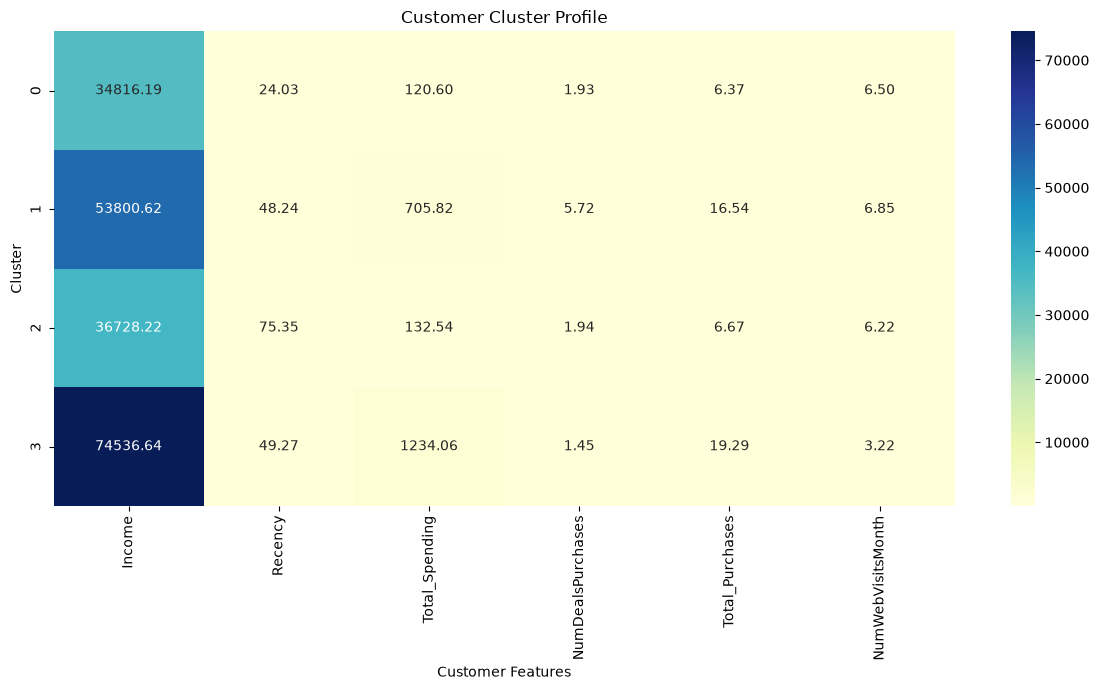

In [29]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    cluster_profile[features],
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Customer Cluster Profile")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")

plt.tight_layout()

plt.savefig(
    "../visuals/cluster_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

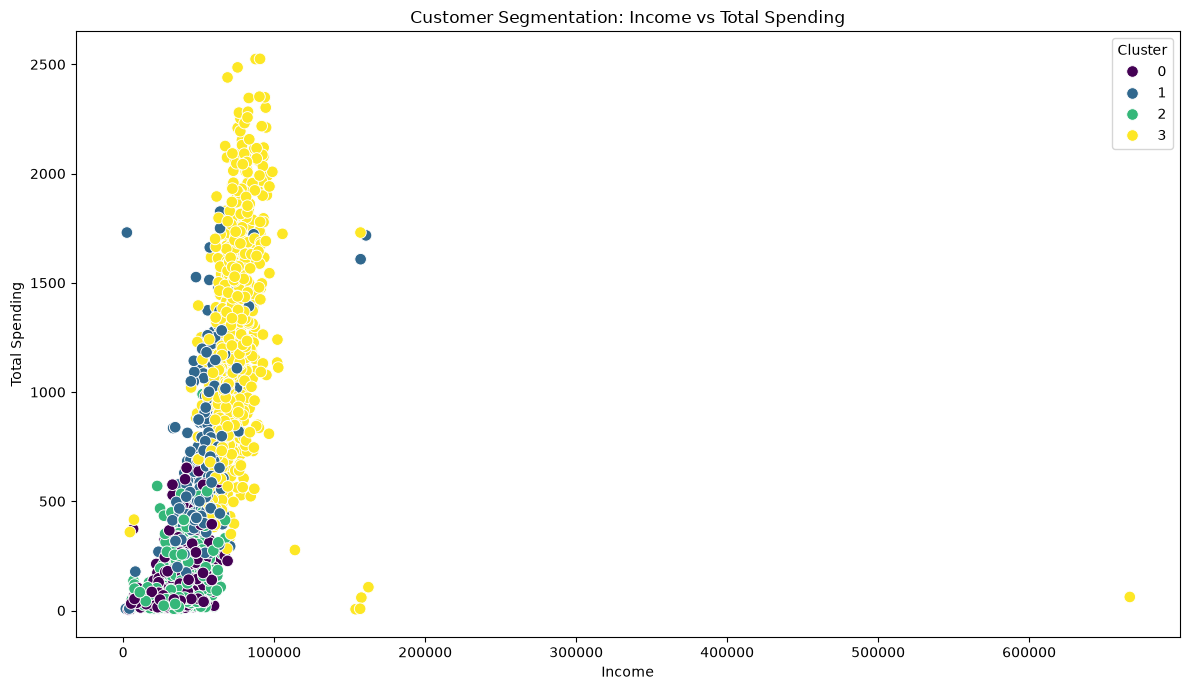

In [30]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Income",
    y="Total_Spending",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title("Customer Segmentation: Income vs Total Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    "../visuals/cluster_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

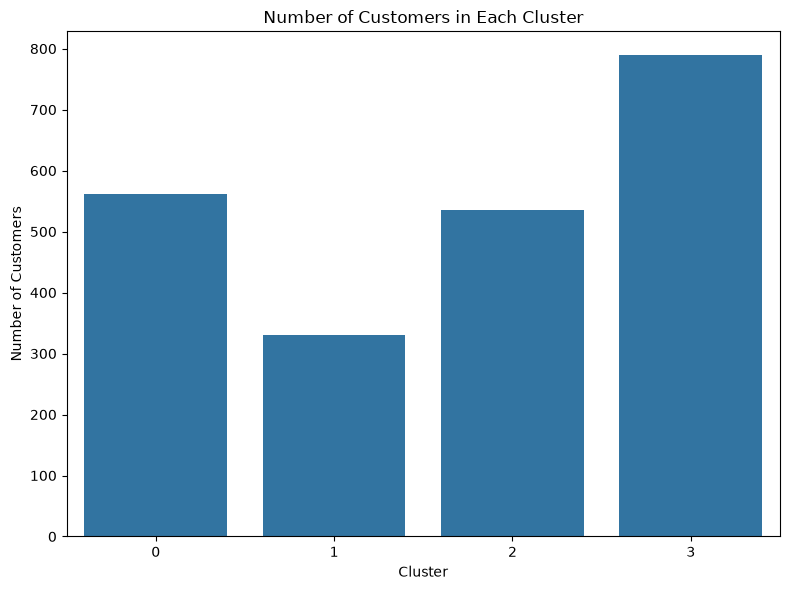

In [31]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Cluster"
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../visuals/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
for cluster in sorted(df["Cluster"].unique()):
    print(f"\n{'=' * 50}")
    print(f"CLUSTER {cluster}")
    print(f"{'=' * 50}")
    
    cluster_data = df[df["Cluster"] == cluster]
    
    print(f"Customers: {len(cluster_data)}")
    print(f"Average Income: ${cluster_data['Income'].mean():,.2f}")
    print(f"Average Recency: {cluster_data['Recency'].mean():.2f} days")
    print(f"Average Total Spending: ${cluster_data['Total_Spending'].mean():,.2f}")
    print(f"Average Total Purchases: {cluster_data['Total_Purchases'].mean():.2f}")
    print(f"Average Deal Purchases: {cluster_data['NumDealsPurchases'].mean():.2f}")
    print(f"Average Web Visits/Month: {cluster_data['NumWebVisitsMonth'].mean():.2f}")


CLUSTER 0
Customers: 562
Average Income: $34,816.19
Average Recency: 24.03 days
Average Total Spending: $120.60
Average Total Purchases: 6.37
Average Deal Purchases: 1.93
Average Web Visits/Month: 6.50

CLUSTER 1
Customers: 330
Average Income: $53,800.62
Average Recency: 48.24 days
Average Total Spending: $705.82
Average Total Purchases: 16.54
Average Deal Purchases: 5.72
Average Web Visits/Month: 6.85

CLUSTER 2
Customers: 535
Average Income: $36,728.22
Average Recency: 75.35 days
Average Total Spending: $132.54
Average Total Purchases: 6.67
Average Deal Purchases: 1.94
Average Web Visits/Month: 6.22

CLUSTER 3
Customers: 789
Average Income: $74,536.64
Average Recency: 49.27 days
Average Total Spending: $1,234.06
Average Total Purchases: 19.29
Average Deal Purchases: 1.45
Average Web Visits/Month: 3.22


In [33]:
output_path = "../data/customer_segments.csv"

df.to_csv(
    output_path,
    index=False
)

print(f"Segmented customer dataset saved to: {output_path}")

Segmented customer dataset saved to: ../data/customer_segments.csv


In [34]:
display(cluster_profile)

,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth,Customer_Count
Cluster,,,,,,,
0,34816.19,24.03,120.60,1.93,6.37,6.50,562
1,53800.62,48.24,705.82,5.72,16.54,6.85,330
2,36728.22,75.35,132.54,1.94,6.67,6.22,535
3,74536.64,49.27,1234.06,1.45,19.29,3.22,789


In [35]:
cluster_names = {
    0: "Loyal Customers",
    1: "Discount Seekers",
    2: "Low Engagement Users",
    3: "High Spenders"
}

df["Customer_Segment"] = df["Cluster"].map(cluster_names)

display(
    df[["ID", "Cluster", "Customer_Segment"]].head(20)
)

,ID,Cluster,Customer_Segment
0,5524,3,High Spenders
1,2174,0,Loyal Customers
2,4141,3,High Spenders
3,6182,0,Loyal Customers
4,5324,1,Discount Seekers
5,7446,3,High Spenders
6,965,1,Discount Seekers
7,6177,0,Loyal Customers
8,4855,0,Loyal Customers
9,5899,2,Low Engagement Users


In [36]:
segment_distribution = (
    df["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Customer_Count")
)

display(segment_distribution)

,Customer_Segment,Customer_Count
0,High Spenders,789
1,Loyal Customers,562
2,Low Engagement Users,535
3,Discount Seekers,330


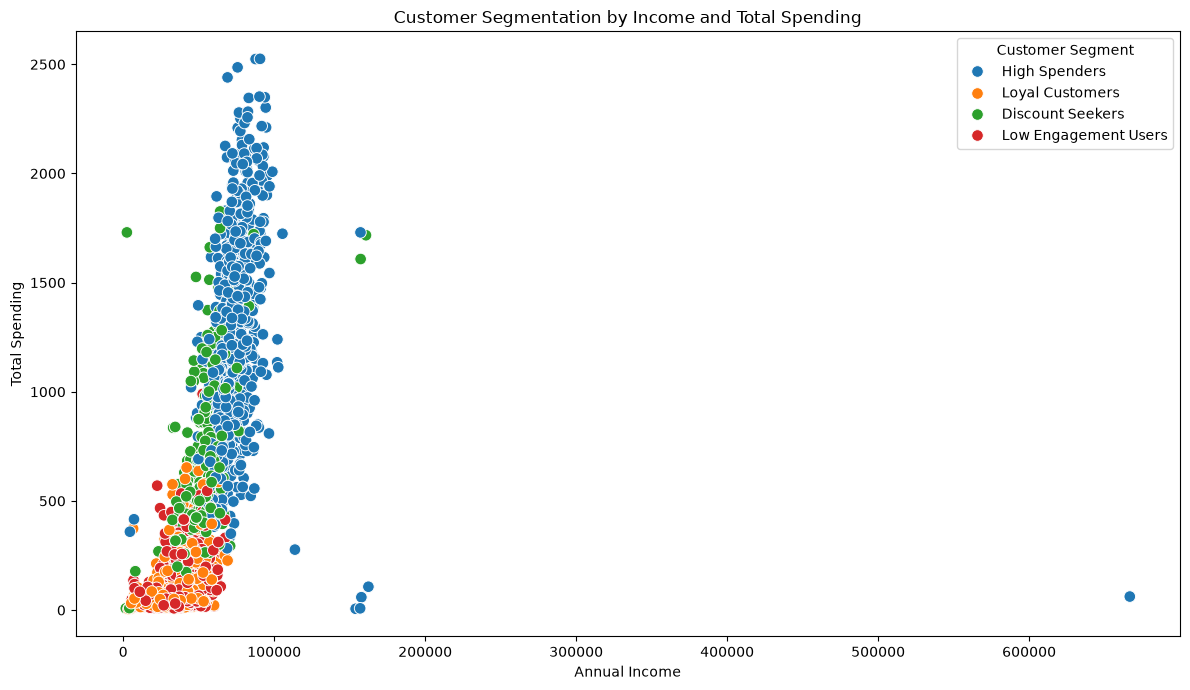

In [37]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Income",
    y="Total_Spending",
    hue="Customer_Segment",
    s=70
)

plt.title("Customer Segmentation by Income and Total Spending")
plt.xlabel("Annual Income")
plt.ylabel("Total Spending")
plt.legend(title="Customer Segment")

plt.tight_layout()

plt.savefig(
    "../visuals/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

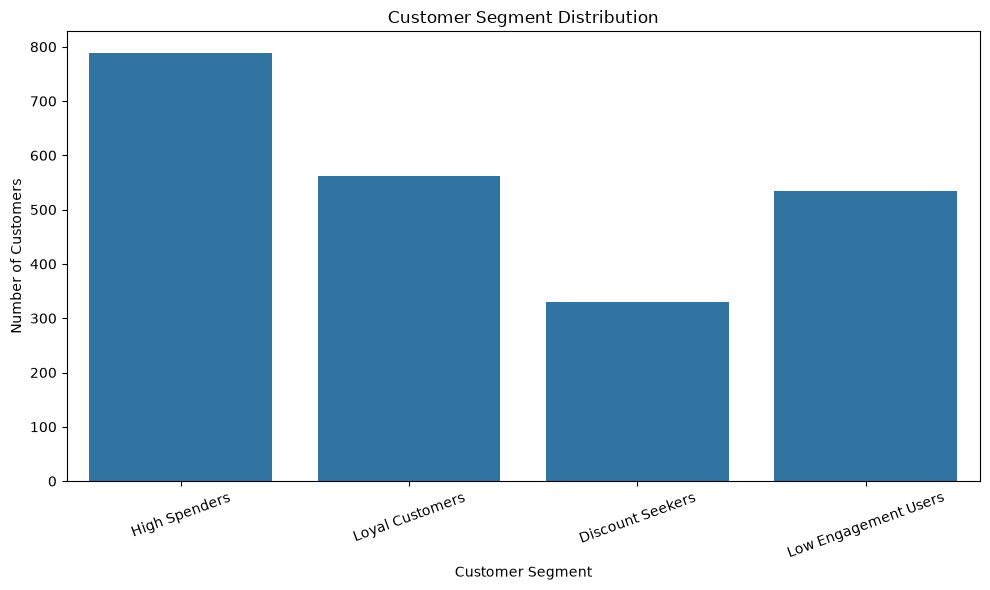

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Customer_Segment",
    order=[
        "High Spenders",
        "Loyal Customers",
        "Discount Seekers",
        "Low Engagement Users"
    ]
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../visuals/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
final_profile = (
    df.groupby("Customer_Segment")[features]
    .mean()
    .round(2)
)

final_profile["Customer_Count"] = (
    df["Customer_Segment"]
    .value_counts()
    .reindex(final_profile.index)
)

display(final_profile)

,Income,Recency,Total_Spending,NumDealsPurchases,Total_Purchases,NumWebVisitsMonth,Customer_Count
Customer_Segment,,,,,,,
Discount Seekers,53800.62,48.24,705.82,5.72,16.54,6.85,330
High Spenders,74536.64,49.27,1234.06,1.45,19.29,3.22,789
Low Engagement Users,36728.22,75.35,132.54,1.94,6.67,6.22,535
Loyal Customers,34816.19,24.03,120.60,1.93,6.37,6.50,562


In [40]:
recommendations = {
    "High Spenders":
        "Prioritize premium products, personalized offers, loyalty rewards, and VIP experiences to maximize customer lifetime value.",
    
    "Loyal Customers":
        "Use loyalty programs, repeat-purchase incentives, and personalized recommendations to maintain engagement and gradually increase spending.",
    
    "Discount Seekers":
        "Target customers with coupons, promotional bundles, seasonal discounts, and deal-based campaigns while protecting profit margins.",
    
    "Low Engagement Users":
        "Launch re-engagement campaigns using personalized offers, reminders, and targeted promotions to encourage customers to return."
}

for segment, recommendation in recommendations.items():
    print(f"\n{segment}")
    print("-" * len(segment))
    print(recommendation)


High Spenders
-------------
Prioritize premium products, personalized offers, loyalty rewards, and VIP experiences to maximize customer lifetime value.

Loyal Customers
---------------
Use loyalty programs, repeat-purchase incentives, and personalized recommendations to maintain engagement and gradually increase spending.

Discount Seekers
----------------
Target customers with coupons, promotional bundles, seasonal discounts, and deal-based campaigns while protecting profit margins.

Low Engagement Users
--------------------
Launch re-engagement campaigns using personalized offers, reminders, and targeted promotions to encourage customers to return.


In [41]:
output_path = "../data/customer_segments.csv"

df.to_csv(
    output_path,
    index=False
)

print(f"Final segmented dataset saved successfully:")
print(output_path)

Final segmented dataset saved successfully:
../data/customer_segments.csv
